In [15]:
import gymnasium as gym 
import numpy as np
import random

import matplotlib.pyplot as plt

In [17]:
gamma = 0.99
epsilon = 0.1
alpha = 0.5
episodes=500

In [18]:
Q = np.zeros((48,4))

In [19]:
#epsilon policy
def epsilon_greedy(state):
    if random.random() < epsilon:
        return env.action_space.sample() #explore
    else:
        return np.argmax(Q[state])

In [59]:
# Q-Learning
all_total_reward=0
all_total_steps=0

episode_reward=[]
for episode in range(episodes):

    render = (episode % 50 ==0)

    if render:
        env = gym.make("CliffWalking-v1",render_mode="human")
    else:
        env = gym.make("CliffWalking-v1")

    done = False
    state,_ = env.reset()

    episode_len = 0
    tot_reward=0

    
    while not done:
        action = epsilon_greedy(state)

        next_state,reward,terminated,truncated,_ = env.step(action)
        done =terminated or truncated 

        #Q-Learning update
        Q[state,action] += alpha * (reward + gamma*np.max(Q[next_state]) - Q[state,action])

        state = next_state

        episode_len += 1
        tot_reward += reward

    all_total_reward+=tot_reward
    all_total_steps+=episode_len
    
    episode_reward.append(tot_reward)
    

    print(f"episode : {episode+1}/500 , total reward = {tot_reward}, steps taken = {episode_len}")
    env.close()

episode : 1/500 , total reward = -15, steps taken = 15
episode : 2/500 , total reward = -234, steps taken = 36
episode : 3/500 , total reward = -13, steps taken = 13
episode : 4/500 , total reward = -13, steps taken = 13
episode : 5/500 , total reward = -17, steps taken = 17
episode : 6/500 , total reward = -13, steps taken = 13
episode : 7/500 , total reward = -14, steps taken = 14
episode : 8/500 , total reward = -15, steps taken = 15
episode : 9/500 , total reward = -15, steps taken = 15
episode : 10/500 , total reward = -13, steps taken = 13
episode : 11/500 , total reward = -13, steps taken = 13
episode : 12/500 , total reward = -13, steps taken = 13
episode : 13/500 , total reward = -13, steps taken = 13
episode : 14/500 , total reward = -15, steps taken = 15
episode : 15/500 , total reward = -15, steps taken = 15
episode : 16/500 , total reward = -15, steps taken = 15
episode : 17/500 , total reward = -326, steps taken = 29
episode : 18/500 , total reward = -233, steps taken = 3

In [60]:
print(f"Average reward = {all_total_reward/500}")
print(f"Average steps = {all_total_steps/500}")

Average reward = -47.354
Average steps = 16.466


In [32]:
# what the model had leaned after 500 episode

env = gym.make("CliffWalking-v1",render_mode = "human")
state,_ = env.reset()
total_reward = 0
episode_len= 0 
done = False

while not done :
    action = np.argmax(Q[state])
    next_state, reward, terminated , truncated,_ = env.step(action)
    done = terminated or truncated

    state = next_state

    episode_len += 1
    total_reward += reward

print(f"total reward : {total_reward} , step taken ={episode_len}")
env.close()

total reward : -13 , step taken =13


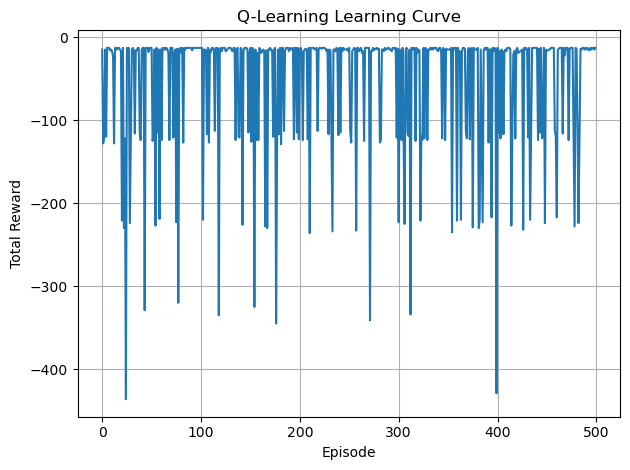

In [58]:
plt.plot(episode_reward)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(True)
plt.title("Q-Learning Learning Curve")
plt.tight_layout()
plt.savefig("./images/QLearning_Learning_Curve.jpg")
plt.show()